<a href="https://colab.research.google.com/github/HamzaBanjanovic/fly-by-wire-simulation/blob/main/simulation/sim1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
a = 4 #the properties of the air causing the angular acceleration to increase, depends on air density, speed squared, wing area, the aircrafts shape, and how hard is it to rotat
b = 1 # how effective the input is, meaning how "strong" the maximum push of the pilots commands are
dt = 0.01
u = 0 # how hard the pilot pulls the stick compared to the maximum he can
theta = 0.01 # nose angle, where the plane is
omega = 0 # angular velocity aka. rotation speed, how fast the plane is turning
alpha = 0 # how hard the plane is being pushed by those forces from a, while they increase as the angle increases amplifying a
times = []
angles = []

'''
new position = old position + speed × little time slice
new speed = old speed + acceleration × little time slice

'''

target = 0 # where we want our nose to be, depending if stable or at a target
I = 0
e_prev = target - theta # initial error, if its
Kp = 10
Ki = 0
Kd = 3



In [ ]:
for i in range(1000):
  e = target - theta # Negative if going up, signalling that the P part needs to go DOWN when influencing u (Kp*e)
  I = I + e*dt # little errors, adding them up over time
  D = (e - e_prev)/dt  # basically omega, just negative, telling us the direction the plane should to to get counterbalanced
  u = Kp*e + Ki*I + Kd*D
  e_prev = e





  alpha = a * theta + b * u # theta times a, acceleration increases ever so slightly
  omega = omega + alpha * dt # speed of rotation infleunced by the push meaning alpha
  theta = theta + omega * dt # current angle influenced by the sum of all previous speeds
  times.append(i * dt) # add the time axis little second by little second
  angles.append(theta) # add how the angle changes over time

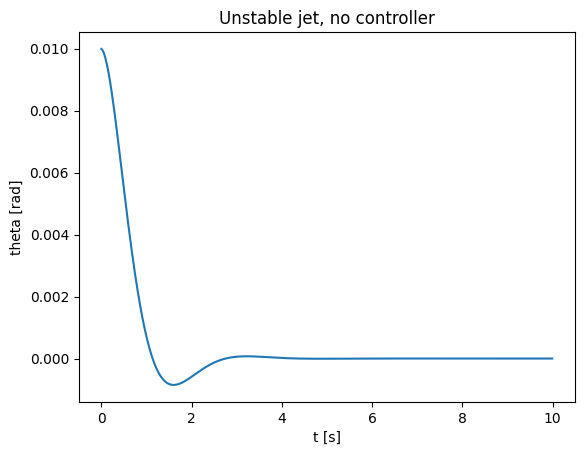

In [ ]:
# Graphing the change of the angle over time using matmatplotlib
import matplotlib.pyplot as plt
plt.plot(times, angles)
plt.xlabel("t [s]")
plt.ylabel("theta [rad]")
plt.title("Unstable jet, no controller")
plt.savefig("figure1.png", dpi=150)
plt.show()